# Bab 7 — Unsupervised Learning
**Practical Statistics for Data Scientists, 2nd Edition** — Peter Bruce, Andrew Bruce & Peter Gedeck (O'Reilly, 2020)

1. Principal Components Analysis (PCA), termasuk correspondence analysis
2. K-Means clustering
3. Hierarchical clustering (dendrogram, ukuran dissimilarity)
4. Model-based clustering (Gaussian mixture, BIC)
5. Scaling dan variabel kategorikal (dominant variables, Gower's distance, masalah data campuran)


In [29]:
%matplotlib inline
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn import preprocessing
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm

DATA = 'https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/'

## Gambaran Besar

**Unsupervised learning** adalah metode statistik yang mencari makna dari data **tanpa variabel target** (tanpa label). Berbeda dengan bab-bab sebelumnya (regresi dan klasifikasi), di sini tidak ada "jawaban benar" yang dipakai untuk melatih model.

Tujuan unsupervised learning:
- **Clustering** — mengelompokkan record yang mirip. Contoh: segmentasi pelanggan, mengelompokkan saham yang bergerak serupa.
- **Reduksi dimensi** — merangkum banyak variabel menjadi lebih sedikit variabel baru yang tetap menyimpan sebagian besar informasi.
- **Eksplorasi data** — memahami struktur data sebelum membangun model prediktif.

Unsupervised learning juga bisa menjadi **bagian dari pipeline supervised**:
- Clustering dipakai untuk membuat fitur baru, atau membangun model terpisah untuk tiap cluster.
- PCA dipakai untuk mengurangi jumlah prediktor sebelum regresi atau klasifikasi.
- Berguna untuk masalah **cold start** (misalnya produk baru tanpa data historis): kelompokkan dulu, lalu gunakan informasi dari cluster yang mirip.

Dalam arti tertentu, unsupervised learning adalah **perluasan EDA** (Bab 1) ke situasi dengan banyak variabel dan banyak record.

## 1. Principal Components Analysis (PCA)

Variabel-variabel sering **berkorelasi**: mereka bergerak bersama dan sebagian informasinya **tumpang tindih** (*redundant*). PCA (Karl Pearson, 1901) adalah teknik untuk menemukan cara variabel-variabel numerik **bervariasi bersama**.

**Istilah kunci:**
- **Principal component** — kombinasi linear dari variabel prediktor.
- **Loadings** — bobot yang mengubah prediktor menjadi komponen (sinonim: weights).
- **Screeplot** — plot varians dari setiap komponen, menunjukkan kepentingan relatif tiap komponen (dalam bentuk varians yang dijelaskan atau proporsinya).

**Ide dasar:** gabungkan banyak prediktor numerik menjadi sekumpulan **kecil** variabel baru, yaitu **principal components (PC)**, yang:
- merupakan kombinasi linear (rata-rata berbobot) dari prediktor asli,
- **tidak saling berkorelasi**,
- tersusun dari yang paling banyak menjelaskan variasi data sampai yang paling sedikit.

Dengan kata lain, PCA mengurangi dimensi data sambil menyimpan **sebanyak mungkin variabilitas**.

### Contoh Sederhana: Dua Saham Minyak
Untuk dua variabel $X_1$ dan $X_2$, ada dua principal components $Z_i$ ($i = 1, 2$):
$$Z_i = w_{i,1} X_1 + w_{i,2} X_2$$
Bobot $(w_{i,1}, w_{i,2})$ adalah **loadings**. Komponen pertama $Z_1$ adalah kombinasi linear yang **paling banyak menjelaskan variasi total**. Komponen kedua $Z_2$ **tegak lurus** (ortogonal) dengan yang pertama dan menjelaskan sisa variasi.

Contoh dari buku: return harian saham **Chevron (CVX)** dan **ExxonMobil (XOM)**.

In [30]:
sp500_px = pd.read_csv(DATA + 'sp500_data.csv.gz', index_col=0)
sp500_sym = pd.read_csv(DATA + 'sp500_sectors.csv')

oil_px = sp500_px[['XOM', 'CVX']]
print(oil_px.shape)

pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns, index=['PC1', 'PC2'])
loadings.round(4)

(5647, 2)


,XOM,CVX
PC1,0.6647,0.7471
PC2,0.7471,-0.6647


- **PC1**: kedua bobot bertanda sama dan besarnya mirip (sekitar 0,66 dan 0,75), artinya PC1 mencerminkan **rata-rata** pergerakan kedua saham. Ini masuk akal karena dua perusahaan minyak besar cenderung naik-turun bersama (dipengaruhi harga minyak dunia).
- **PC2**: bobotnya berlawanan tanda, artinya PC2 menangkap **saat kedua saham bergerak berbeda arah** (divergensi).

**Catatan:** tanda (positif/negatif) loadings bersifat arbitrer. Di buku, loadings PC1 tercetak negatif (−0,66 dan −0,75), sedangkan di sini positif. Keduanya sama saja: mengalikan seluruh komponen dengan −1 tidak mengubah artinya.

Kita bisa memvisualisasikan arah kedua komponen di atas scatterplot data:

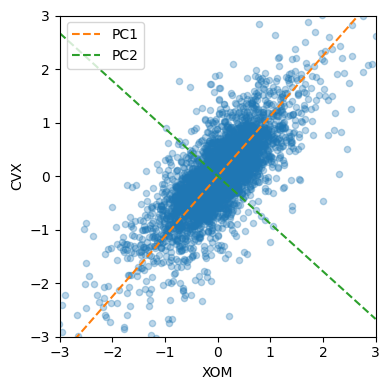

In [31]:
def abline(slope, intercept, ax):
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4, 4))
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc['PC1', 'CVX'] / loadings.loc['PC1', 'XOM'], 0, ax), '--', color='C1', label='PC1')
ax.plot(*abline(loadings.loc['PC2', 'CVX'] / loadings.loc['PC2', 'XOM'], 0, ax), '--', color='C2', label='PC2')
ax.legend()
plt.tight_layout(); plt.show()

Garis PC1 mengikuti arah sebaran data yang paling panjang (arah variasi terbesar). Garis PC2 tegak lurus dengan PC1.

### Menghitung Principal Components
Untuk lebih dari dua variabel, prosesnya:
1. Buat komponen pertama: kombinasi linear prediktor yang memaksimalkan **persentase varians total** yang dijelaskan.
2. Komponen pertama menjadi prediktor "baru" $Z_1$.
3. Ulangi untuk komponen berikutnya, dengan syarat **tidak berkorelasi** dengan komponen sebelumnya, sampai jumlah komponen sama dengan jumlah variabel asli.
4. Simpan hanya beberapa komponen pertama yang menjelaskan sebagian besar varians.

Secara matematis, loadings adalah **eigenvector** dari matriks kovarians (atau korelasi) data, dan varians tiap komponen adalah **eigenvalue**-nya.

### Menafsirkan Principal Components
Contoh lebih besar: return harian 16 saham dari berbagai sektor (teknologi, energi, keuangan, ritel). **Screeplot** memperlihatkan seberapa banyak varians yang dijelaskan tiap komponen.

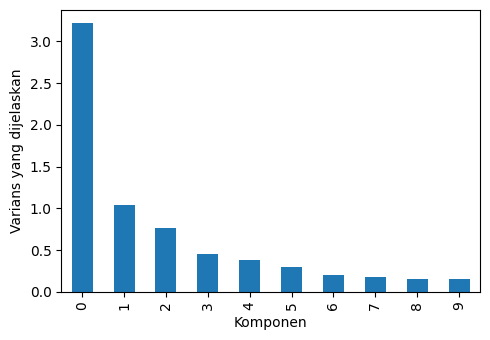

Proporsi varians kumulatif (5 komponen pertama): [0.445 0.588 0.693 0.755 0.809]


In [32]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(5, 3.5))
ax.set_xlabel('Komponen'); ax.set_ylabel('Varians yang dijelaskan')
plt.tight_layout(); plt.show()

print('Proporsi varians kumulatif (5 komponen pertama):',
      np.cumsum(sp_pca.explained_variance_ratio_[:5]).round(3))

Varians komponen pertama jauh lebih besar dari yang lain, dan biasanya hanya beberapa komponen pertama yang benar-benar penting. Pola menurun tajam lalu landai seperti ini ("siku") adalah ciri khas screeplot, dan titik "siku" sering dipakai untuk menentukan berapa komponen yang disimpan.

Untuk menafsirkan komponen, lihat **loadings**-nya:

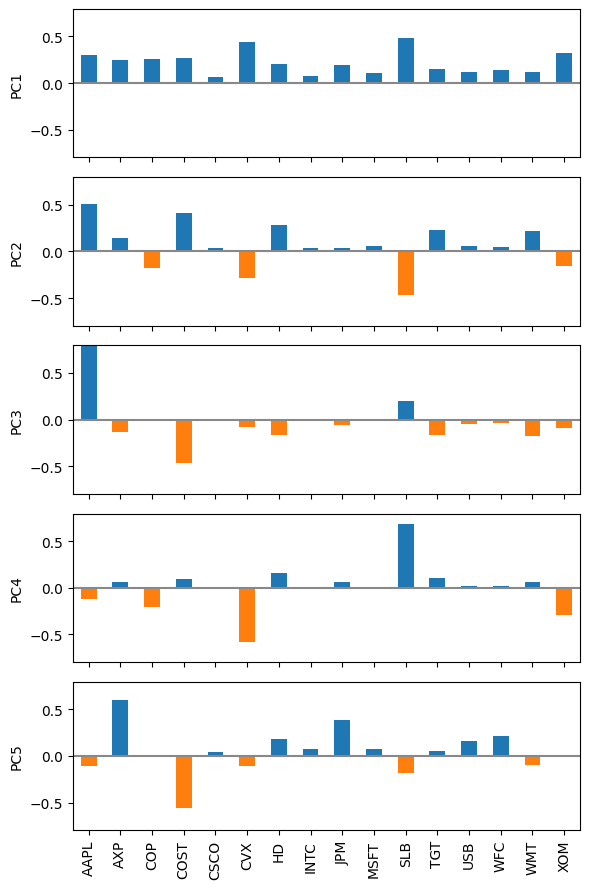

In [33]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :], columns=top_sp.columns)
maxPC = 1.01 * np.max(np.max(np.abs(loadings.loc[0:5, :])))

f, axes = plt.subplots(5, 1, figsize=(6, 9), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i + 1}')
    ax.set_ylim(-maxPC, maxPC)
plt.tight_layout(); plt.show()

**Interpretasi:**
- **PC1**: semua loadings bertanda sama (positif) → PC1 adalah **rata-rata pasar** secara keseluruhan ("market factor"). Wajar karena sebagian besar saham cenderung naik-turun bersama pasar.
- **PC2**: saham **energi** (CVX, XOM, SLB, COP) bertanda negatif, sedangkan saham seperti AAPL, COST, dan HD positif. PC2 menangkap **perbedaan sektor energi dibanding sektor lain**.
- **PC3**: terutama kontras antara pergerakan **Apple** (positif besar) dan **Costco** (negatif).
- **PC4**: kontras **Schlumberger (SLB)** dengan saham energi lain (CVX dan XOM).
- **PC5**: saham **keuangan** seperti AXP dan JPM bertanda positif, berlawanan dengan COST.

Pelajaran: PCA tidak hanya mengurangi dimensi, tapi juga bisa **mengungkap struktur** tersembunyi dalam data, seperti sektor industri.

**Berapa komponen yang dipilih?**
- Lihat **screeplot** dan pilih komponen sebelum "siku".
- Pilih komponen yang secara kumulatif menjelaskan persentase varians tertentu (misalnya 80%).
- Lihat loadings untuk memilih komponen yang **bisa ditafsirkan**.
- Jika PCA dipakai untuk model prediktif, pilih jumlah komponen dengan **cross-validation**.

### Correspondence Analysis
PCA tidak bisa dipakai langsung untuk data **kategorikal**. Versi PCA untuk data kategorikal adalah **correspondence analysis (CA)**. Tujuannya: menemukan hubungan antar kategori atau antar variabel kategorikal, dan memvisualisasikannya dalam bentuk **biplot**.

CA umumnya dipakai untuk **analisis grafis** dari tabel kontingensi dua arah, bukan untuk reduksi dimensi sebelum modeling.

Contoh dari buku: data `housetasks`, tabel kontingensi tentang siapa yang mengerjakan tugas rumah tangga (istri, suami, bergantian, atau bersama).

In [34]:
housetasks = pd.read_csv(DATA + 'housetasks.csv', index_col=0)
housetasks

,Wife,Alternating,Husband,Jointly
Task,,,,
Laundry,156,14,2,4
Main_meal,124,20,5,4
Dinner,77,11,7,13
Breakfast,82,36,15,7
Tidying,53,11,1,57
Dishes,32,24,4,53
Shopping,33,23,9,55
Official,12,46,23,15
Driving,10,51,75,3


**Cara kerja CA (versi ringkas):**
1. Ubah tabel hitungan menjadi tabel **proporsi** $P$ (dibagi total).
2. Hitung massa baris $r$ dan kolom $c$ (jumlah proporsi per baris/kolom).
3. Hitung **standardized residual**: $S = D_r^{-1/2}(P - rc^T)D_c^{-1/2}$. Ini mirip Pearson residual pada chi-square test (Bab 3).
4. Lakukan **singular value decomposition (SVD)** pada $S$. Dua dimensi pertama dipakai untuk biplot.

Di Python, CA tersedia di paket `prince`. Supaya tidak bergantung pada paket tambahan dan cara kerjanya terlihat, di sini kita hitung manual dengan NumPy.

In [35]:
N = housetasks.values.astype(float)
P = N / N.sum()
r = P.sum(axis=1)
c = P.sum(axis=0)
S = np.diag(r ** -0.5) @ (P - np.outer(r, c)) @ np.diag(c ** -0.5)

U, sv, Vt = np.linalg.svd(S, full_matrices=False)
row_coords = np.diag(r ** -0.5) @ U * sv
col_coords = np.diag(c ** -0.5) @ Vt.T * sv

inertia = sv ** 2
print('Proporsi inertia per dimensi:', (inertia / inertia.sum()).round(3))

Proporsi inertia per dimensi: [0.487 0.399 0.114 0.   ]


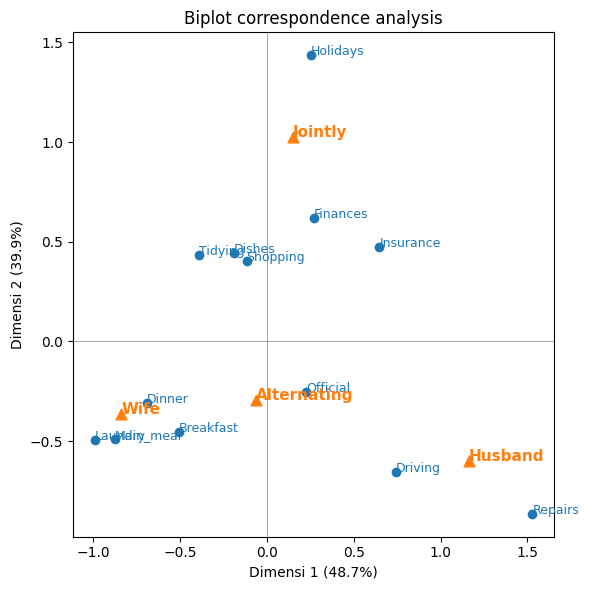

In [36]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(row_coords[:, 0], row_coords[:, 1], color='C0')
for i, name in enumerate(housetasks.index):
    ax.annotate(name, (row_coords[i, 0], row_coords[i, 1]), color='C0', fontsize=9)
ax.scatter(col_coords[:, 0], col_coords[:, 1], color='C1', marker='^', s=60)
for j, name in enumerate(housetasks.columns):
    ax.annotate(name, (col_coords[j, 0], col_coords[j, 1]), color='C1', fontsize=11, fontweight='bold')
ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
pct = inertia / inertia.sum() * 100
ax.set_xlabel(f'Dimensi 1 ({pct[0]:.1f}%)'); ax.set_ylabel(f'Dimensi 2 ({pct[1]:.1f}%)')
ax.set_title('Biplot correspondence analysis')
plt.tight_layout(); plt.show()

**Cara membaca biplot:** kategori yang posisinya **berdekatan** cenderung muncul bersama. Hasilnya:
- Tugas seperti mencuci (*Laundry*), memasak (*Main_meal*, *Dinner*), dan sarapan dekat dengan **Wife** (istri).
- Tugas seperti perbaikan rumah (*Repairs*) dekat dengan **Husband** (suami).
- Tugas seperti liburan (*Holidays*), keuangan (*Finances*), dan asuransi (*Insurance*) dekat dengan **Jointly** (bersama).

Dua dimensi pertama sudah menjelaskan hampir 90% "inertia" (analog varians dalam PCA), jadi biplot 2D ini sudah mewakili sebagian besar struktur data.

## 2. K-Means Clustering

**Clustering** adalah teknik membagi data ke dalam kelompok-kelompok, di mana record **dalam satu kelompok mirip** satu sama lain. Tujuannya: menemukan kelompok yang **bermakna**.

**K-Means** adalah metode clustering pertama yang dikembangkan dan masih sangat populer karena sederhana dan bisa diskalakan ke data besar.

**Istilah kunci:**
- **Cluster** — kelompok record yang mirip.
- **Cluster mean** — vektor rata-rata variabel untuk record dalam satu cluster (disebut juga **centroid**).
- **K** — jumlah cluster.

K-Means membagi data ke dalam **K cluster** dengan meminimalkan **jumlah kuadrat jarak** setiap record ke **mean cluster**-nya (*within-cluster sum of squares*).

### Contoh Sederhana: Dua Saham Minyak
Misalkan ada $n$ record dengan dua variabel $x$ dan $y$, dan kita ingin $K = 4$ cluster. Untuk cluster $k$ dengan $n_k$ record, mean-nya $(\bar{x}_k, \bar{y}_k)$:
$$\bar{x}_k = \frac{1}{n_k}\sum_{i \in \text{Cluster } k} x_i \qquad \bar{y}_k = \frac{1}{n_k}\sum_{i \in \text{Cluster } k} y_i$$

Jumlah kuadrat dalam cluster:
$$SS_k = \sum_{i \in \text{Cluster } k} (x_i - \bar{x}_k)^2 + (y_i - \bar{y}_k)^2$$

K-Means mencari pembagian yang meminimalkan $SS_1 + SS_2 + \dots + SS_K$.

**Catatan:** K-Means **tidak menjamin** cluster berukuran sama, tetapi menghasilkan cluster yang terpisah sebaik mungkin. Variabel juga biasanya perlu **dinormalisasi** (lihat bagian 5), kecuali jika skalanya memang sama seperti return saham.

In [37]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df)
df['cluster'] = kmeans.labels_
print(df.head())

centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
print('\nCluster means (centroid):')
print(centers.round(4))

                 XOM       CVX  cluster
2011-01-03  0.736805  0.240681        3
2011-01-04  0.168668 -0.584516        0
2011-01-05  0.026631  0.446985        3
2011-01-06  0.248558 -0.919751        0
2011-01-07  0.337329  0.180511        3

Cluster means (centroid):
      XOM     CVX
0 -0.3285 -0.5669
1 -1.1440 -1.7503
2  0.9583  1.3742
3  0.2420  0.3352


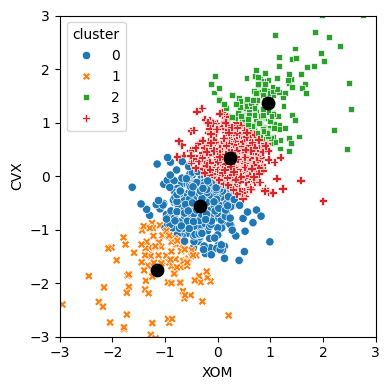

In [38]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster', ax=ax, data=df, palette='tab10')
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=80, color='black')
plt.tight_layout(); plt.show()

Cluster yang terbentuk menangkap kondisi pasar yang berbeda:
- Hari ketika **kedua saham naik** (pasar naik).
- Hari ketika **kedua saham turun** (pasar turun).
- Dua cluster lain untuk hari ketika keduanya bergerak **relatif kecil** atau **berbeda arah**.

### Algoritma K-Means
Mencari solusi optimal yang eksak sangat sulit secara komputasi, jadi dipakai algoritma heuristik yang efisien:
1. Mulai dengan **K mean cluster** awal (bisa dipilih acak).
2. **Tetapkan** setiap record ke cluster dengan mean **terdekat**.
3. **Hitung ulang** mean cluster berdasarkan record yang baru ditetapkan.
4. Ulangi langkah 2–3 sampai penetapan record **tidak berubah lagi** (konvergen).

Karena hasilnya bisa bergantung pada titik awal, algoritma biasanya dijalankan **berkali-kali** dengan titik awal acak berbeda, lalu dipilih hasil terbaik (SS terkecil). Di scikit-learn, ini diatur oleh `n_init`. Inisialisasi default-nya adalah **k-means++**, yang memilih titik awal yang saling berjauhan.

### Menafsirkan Cluster
Contoh lebih besar: 16 saham, 5 cluster. Setiap record adalah **satu hari perdagangan**, dan variabelnya adalah return 16 saham.

In [39]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
kmeans = KMeans(n_clusters=5, n_init=10, random_state=1).fit(top_sp)

from collections import Counter
print('Ukuran tiap cluster:', {int(k): int(v) for k, v in sorted(Counter(kmeans.labels_).items())})

Ukuran tiap cluster: {0: 272, 1: 301, 2: 158, 3: 113, 4: 287}


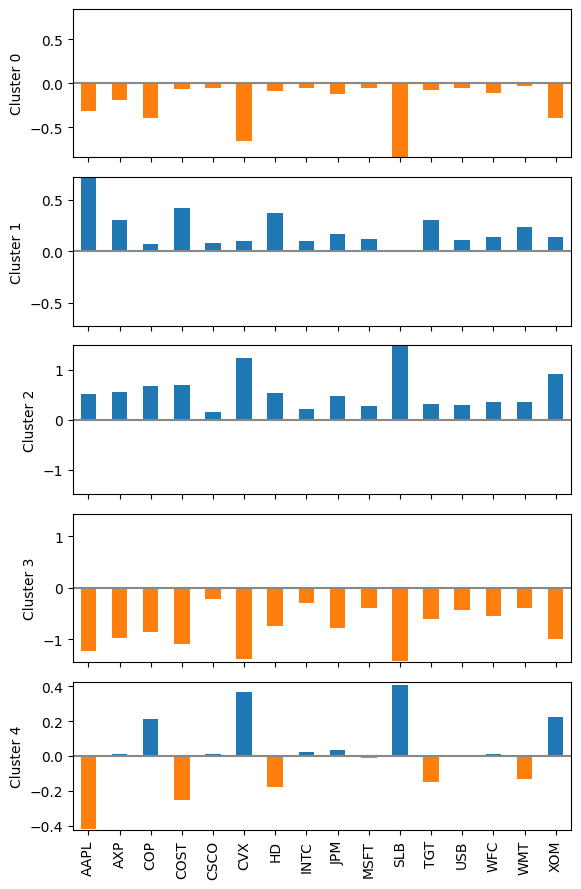

In [40]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)
f, axes = plt.subplots(5, 1, figsize=(6, 9), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i}')
    ax.set_ylim(-maxPC, maxPC)
plt.tight_layout(); plt.show()

**Interpretasi:** setiap panel adalah **profil rata-rata return** untuk satu cluster (biru = naik, oranye = turun):
- **Cluster 2**: hampir semua saham naik besar → hari **pasar naik kuat**.
- **Cluster 3**: hampir semua saham turun besar → hari **pasar turun tajam**.
- **Cluster 0**: penurunan terutama di saham **energi** (SLB, CVX, XOM, COP) → hari ketika sektor energi melemah.
- **Cluster 4**: saham **energi naik** sementara AAPL dan saham ritel turun → hari ketika sektor energi bergerak berlawanan dengan sektor lain.
- **Cluster 1**: kenaikan moderat, terutama AAPL, COST, dan HD, dengan energi hampir datar → hari ketika saham non-energi menguat.

Hasil ini mirip dengan temuan PCA: struktur sektor muncul secara alami dari data. Bedanya, PCA menghasilkan **arah variasi**, sedangkan K-Means menghasilkan **kelompok record**.

**Catatan:** nomor cluster (0, 1, 2, ...) bersifat arbitrer. Di versi scikit-learn lain (misalnya di Colab), nomornya bisa tertukar walaupun polanya sama. Jadi cocokkan interpretasi di atas berdasarkan **pola** di tiap panel (semua naik, semua turun, energi saja, dan seterusnya), bukan berdasarkan nomor clusternya.

### Memilih Jumlah Cluster (K)
K bisa ditentukan berdasarkan kebutuhan praktis (misalnya tim marketing hanya sanggup menangani 4 segmen pelanggan). Jika tidak ada batasan itu, metode statistik bisa membantu.

**Elbow method:** lihat kapan penambahan cluster tidak lagi banyak menambah **varians yang dijelaskan**. Plot inertia (within-cluster SS) terhadap K, lalu cari titik "siku" di mana penurunan mulai melandai.

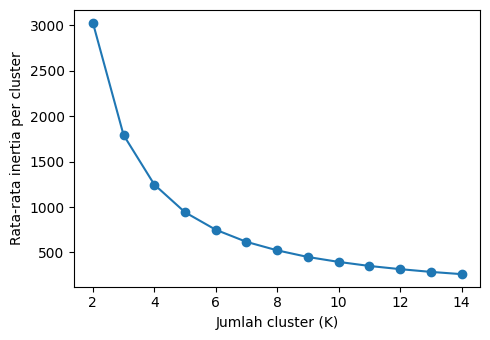

In [41]:
inertia = []
for n_clusters in range(2, 15):
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit(top_sp)
    inertia.append(km.inertia_ / n_clusters)
inertias = pd.DataFrame({'n_clusters': range(2, 15), 'inertia': inertia})

ax = inertias.plot(x='n_clusters', y='inertia', marker='o', legend=False, figsize=(5, 3.5))
ax.set_xlabel('Jumlah cluster (K)'); ax.set_ylabel('Rata-rata inertia per cluster')
plt.tight_layout(); plt.show()

Dalam kasus ini, elbow tidak terlalu jelas: penurunan cukup cepat sampai sekitar 3–5 cluster, lalu melandai. Ini **sangat umum** di data nyata. Buku menekankan bahwa elbow method sering kali tidak memberikan jawaban tegas, dan pada akhirnya pemilihan K juga harus mempertimbangkan **apakah cluster yang dihasilkan bisa ditafsirkan dan berguna**.

Alternatif lain untuk memilih K:
- **Gap statistic** dan **silhouette score**.
- **Model-based clustering** dengan kriteria BIC (bagian 4).
- **Stabilitas cluster**: apakah cluster tetap konsisten jika dijalankan pada sampel data yang berbeda?

## 3. Hierarchical Clustering

**Hierarchical clustering** adalah alternatif K-Means yang bisa menghasilkan cluster sangat berbeda. Kelebihannya:
- **Tidak perlu menentukan K di awal**. Kita bisa melihat efek berbagai jumlah cluster sekaligus.
- Hasilnya bisa divisualisasikan secara intuitif dengan **dendrogram**.
- Lebih sensitif terhadap **outlier**, sehingga bisa membantu mendeteksinya.

Kelemahannya: **tidak bisa diskalakan** ke data sangat besar (jutaan record), karena harus menghitung jarak antar semua pasangan record. Untuk data berukuran sedang (puluhan ribu), algoritma ini cukup cepat.

**Istilah kunci:**
- **Dendrogram** — representasi visual dari record dan hierarki cluster tempat mereka bergabung.
- **Distance** — ukuran seberapa dekat satu record dengan record lain.
- **Dissimilarity** — ukuran seberapa dekat satu **cluster** dengan cluster lain.

### Contoh Sederhana: Mengelompokkan Perusahaan
Berbeda dengan contoh K-Means (yang mengelompokkan **hari**), di sini kita mengelompokkan **perusahaan** berdasarkan kemiripan pergerakan saham mereka. Jadi data perlu ditranspose: baris = perusahaan, kolom = hari.

In [42]:
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()
print(df.shape)

Z = linkage(df, method='complete')

(18, 1131)


### Dendrogram

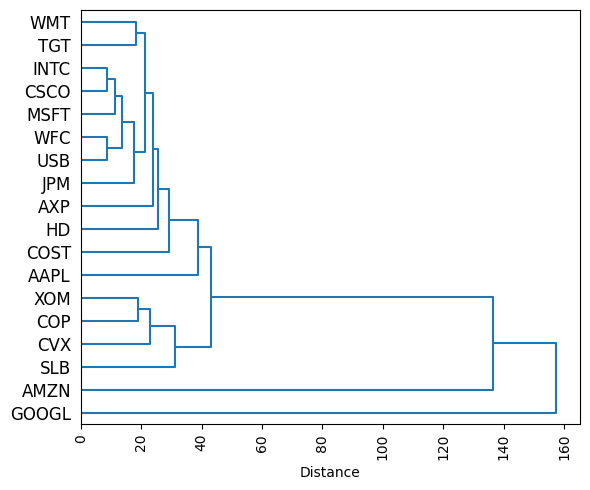

In [43]:
fig, ax = plt.subplots(figsize=(6, 5))
dendrogram(Z, labels=list(df.index), orientation='right', ax=ax, color_threshold=0)
plt.xticks(rotation=90)
ax.set_xlabel('Distance')
plt.tight_layout(); plt.show()

**Cara membaca dendrogram:**
- Setiap daun (ujung) adalah satu perusahaan.
- Perusahaan yang **bergabung lebih awal** (di jarak kecil) paling mirip.
- Panjang cabang menunjukkan **tingkat dissimilarity** saat dua cluster digabung.

Hasilnya:
- Saham **minyak** (XOM, COP, CVX, SLB) membentuk satu kelompok yang jelas.
- Pasangan dari sektor yang sama bergabung paling awal: **WFC–USB** (bank), **INTC–CSCO** (teknologi), dan **WMT–TGT** (ritel).
- **AMZN** dan **GOOGL** sangat terpisah dari yang lain dan baru bergabung di jarak sangat besar. Ini bukan karena keduanya "unik", tetapi karena harga sahamnya tinggi sehingga return hariannya (dalam dolar) bervariasi jauh lebih besar. Masalah **variabel dominan** ini dibahas di bagian 5.

Untuk mendapatkan sejumlah cluster tertentu, **potong** dendrogram secara horizontal. Misalnya untuk 4 cluster:

In [44]:
memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"Cluster {key}: {', '.join(item.index)}")

Cluster 1: COP, CVX, SLB, XOM
Cluster 2: AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
Cluster 3: AMZN
Cluster 4: GOOGL


### Algoritma Agglomerative
Hierarchical clustering yang paling umum adalah **agglomerative** (bottom-up):
1. Mulai dengan setiap record sebagai **cluster sendiri** (n cluster berisi satu record).
2. Hitung **dissimilarity** $D(C_k, C_\ell)$ antara semua pasangan cluster.
3. **Gabungkan** dua cluster yang paling mirip (dissimilarity terkecil).
4. Ulangi langkah 2–3 sampai tersisa **satu cluster** yang berisi semua record.

Untuk mengukur dissimilarity dua cluster $A$ dan $B$ (masing-masing berisi beberapa record), dibutuhkan **jarak antar record** $d(a_i, b_j)$ (misalnya Euclidean) lalu aturan menggabungkannya.

### Ukuran Dissimilarity (Linkage)
| Metode | Definisi | Karakteristik |
|---|---|---|
| **Complete linkage** | Jarak **maksimum** antar semua pasangan record | Cluster cenderung berukuran sama dan kompak |
| **Single linkage** | Jarak **minimum** antar semua pasangan record | Cenderung membentuk cluster "berantai" yang tidak seimbang (*chaining*) |
| **Average linkage** | **Rata-rata** jarak semua pasangan | Kompromi antara single dan complete |
| **Ward's method** | Meminimalkan peningkatan **within-cluster sum of squares** | Mirip K-Means; cluster cenderung kompak |

Rumus complete linkage:
$$D(A, B) = \max d(a_i, b_j) \text{ untuk semua pasangan } i, j$$

Contoh dari buku: membandingkan keempat metode pada data return harian XOM dan CVX, dipotong menjadi 4 cluster.

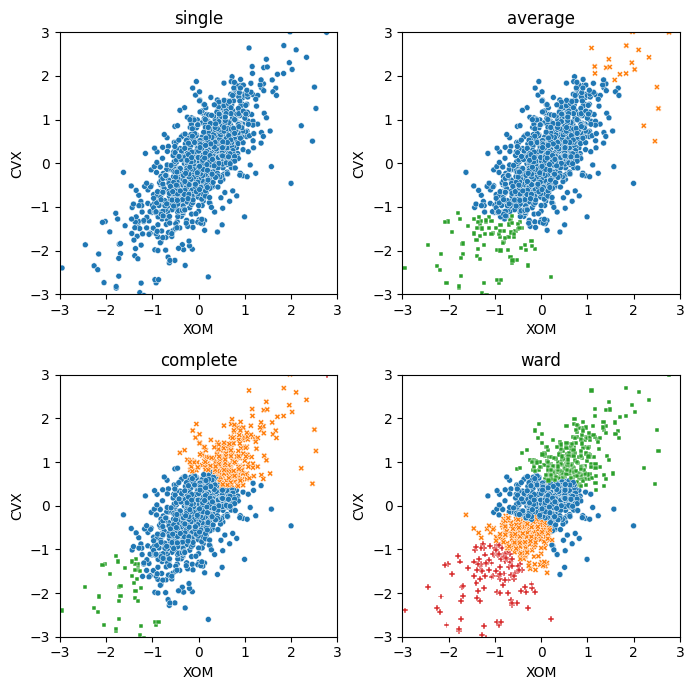

In [45]:
df_oil = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]

fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for i, method in enumerate(['single', 'average', 'complete', 'ward']):
    ax = axes[i // 2, i % 2]
    Z_oil = linkage(df_oil, method=method)
    colors = [f'C{c + 1}' for c in fcluster(Z_oil, 4, criterion='maxclust')]
    ax = sns.scatterplot(x='XOM', y='CVX', hue=colors, style=colors, size=0.5, ax=ax,
                         data=df_oil, legend=False)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_title(method)
plt.tight_layout(); plt.show()

- **Single linkage** hampir menempatkan semua record ke satu cluster besar; cluster lain hanya berisi beberapa outlier. Ini efek *chaining*.
- **Average linkage** sedikit lebih seimbang, tapi masih didominasi satu cluster.
- **Complete linkage** dan **Ward** menghasilkan cluster yang lebih seimbang dan lebih mirip hasil K-Means.

Pemilihan metode linkage bisa sangat memengaruhi hasil. Single linkage berguna untuk **mendeteksi outlier**, sedangkan complete dan Ward lebih cocok untuk **segmentasi**.

## 4. Model-Based Clustering

Metode clustering sebelumnya (K-Means dan hierarchical) bersifat **heuristik**: berbasis jarak, tanpa model probabilitas. **Model-based clustering** dikembangkan oleh Adrian Raftery dkk. dan berbasis **statistik**: data diasumsikan berasal dari **campuran (mixture) beberapa distribusi probabilitas**.

Keuntungannya: kita bisa memakai **kriteria statistik** (seperti BIC) untuk menentukan jumlah dan bentuk cluster.

### Distribusi Normal Multivariat
Model yang paling umum mengasumsikan setiap cluster berdistribusi **normal multivariat** (perluasan distribusi normal ke $p$ variabel). Untuk $p$ variabel $X = X_1, \dots, X_p$, distribusinya ditentukan oleh:
- **vektor mean** $\mu = \mu_1, \dots, \mu_p$, dan
- **matriks kovarians** $\Sigma$ (varians tiap variabel di diagonal, kovarians antar variabel di luar diagonal).

$$X \sim N_p(\mu, \Sigma)$$

Kurva kontur distribusi normal multivariat 2D berbentuk **elips**. Bentuk, orientasi, dan ukuran elips ditentukan oleh matriks kovarians.

### Mixture of Normals (Gaussian Mixture Model)
Ide utama: setiap record diasumsikan berasal dari **salah satu dari K distribusi normal multivariat**, masing-masing dengan mean $\mu_k$ dan kovarians $\Sigma_k$ berbeda. Model mengestimasi:
- parameter tiap distribusi ($\mu_k$, $\Sigma_k$), dan
- **probabilitas** setiap record berasal dari tiap distribusi.

Algoritma yang dipakai adalah **Expectation-Maximization (EM)**.

Di Python: `sklearn.mixture.GaussianMixture`.

In [46]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2, random_state=1).fit(df)
print('Means:')
print(pd.DataFrame(mclust.means_, columns=['XOM', 'CVX']).round(4))
print('\nCovariances:')
print(mclust.covariances_.round(4))

Means:
      XOM     CVX
0 -0.0503 -0.2116
1  0.0725  0.1049

Covariances:
[[[0.9712 0.9776]
  [0.9776 1.6723]]

 [[0.2682 0.2756]
  [0.2756 0.5168]]]


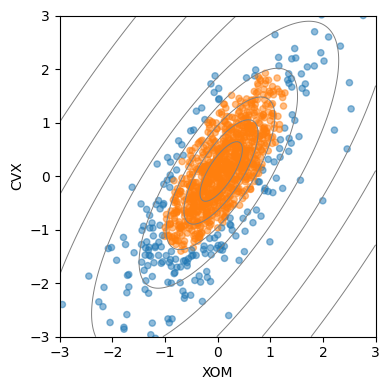

In [47]:
fig, ax = plt.subplots(figsize=(4, 4))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)

# Gambar kontur elips tiap komponen
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = -mclust.score_samples(pd.DataFrame(grid, columns=['XOM', 'CVX'])).reshape(xx.shape)
ax.contour(xx, yy, zz, levels=np.logspace(0, 1.3, 8), colors='gray', linewidths=0.7)
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

Hasilnya menarik: kedua cluster punya **mean hampir sama** (sekitar nol), tapi **kovarians sangat berbeda**:
- Satu cluster dengan **varians kecil** → hari-hari "normal" dengan pergerakan kecil.
- Satu cluster dengan **varians besar** → hari-hari dengan pergerakan besar (volatil), yang membentuk "ekor" distribusi.

Ini berbeda dengan K-Means, yang selalu mencari cluster berdasarkan **perbedaan mean**. Model-based clustering bisa menemukan cluster berdasarkan **bentuk sebaran** (varians/kovarians). Ini juga terkait dengan konsep distribusi **long-tailed** dari Bab 2: return saham bisa dilihat sebagai campuran hari tenang dan hari bergejolak.

### Memilih Jumlah Cluster dengan BIC
Model-based clustering memungkinkan kita memilih jumlah cluster dan **jenis matriks kovarians** dengan kriteria statistik, yaitu **Bayesian Information Criterion (BIC)**. BIC mirip AIC (Bab 4), tetapi dengan penalti lebih besar untuk model kompleks. **Semakin kecil BIC, semakin baik** (di scikit-learn).

Jenis matriks kovarians di `GaussianMixture`:
- `full` — setiap komponen punya matriks kovarians sendiri (paling fleksibel).
- `tied` — semua komponen berbagi matriks kovarians yang sama.
- `diag` — kovarians diagonal (variabel dianggap tidak berkorelasi dalam cluster).
- `spherical` — satu varians per komponen (bentuk lingkaran).

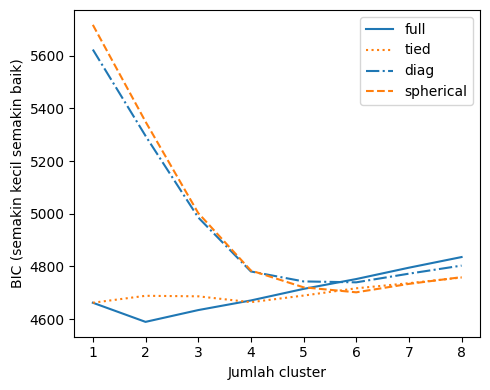

Model terbaik: 2 cluster, covariance_type = 'full'


In [48]:
results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components=n_components, warm_start=True,
                                 covariance_type=covariance_type, random_state=1)
        mclust.fit(df)
        results.append({'bic': mclust.bic(df), 'n_components': n_components,
                        'covariance_type': covariance_type})
results = pd.DataFrame(results)

colors = ['C0', 'C1', 'C2', 'C3']
styles = ['C0-', 'C1:', 'C0-.', 'C1--']
fig, ax = plt.subplots(figsize=(5, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type, kind='line', style=styles[i])
ax.set_xlabel('Jumlah cluster'); ax.set_ylabel('BIC (semakin kecil semakin baik)')
plt.tight_layout(); plt.show()

best = results.loc[results.bic.idxmin()]
print(f"Model terbaik: {int(best.n_components)} cluster, covariance_type = '{best.covariance_type}'")

BIC memilih model dengan **2 cluster** dan kovarians `full`, cocok dengan interpretasi di atas: campuran hari "tenang" dan hari "bergejolak". Dalam analisis lain (termasuk versi R di buku dengan paket `mclust`), BIC bisa memilih jumlah cluster yang lebih banyak. Buku mengingatkan beberapa hal:

**Keterbatasan model-based clustering:**
- Asumsinya: data berasal dari campuran distribusi **normal**. Data nyata (terutama yang long-tailed seperti return saham) sering tidak memenuhi asumsi ini, sehingga BIC cenderung memilih **lebih banyak cluster** hanya untuk "menambal" ekor distribusi, bukan karena ada kelompok yang bermakna.
- Butuh lebih banyak komputasi dibanding K-Means atau hierarchical.
- Hasilnya bisa sulit ditafsirkan jika jumlah komponennya banyak.

Model-based clustering adalah area yang aktif berkembang, dengan banyak perluasan (misalnya mixture distribusi non-normal).

## 5. Scaling dan Variabel Kategorikal

Teknik unsupervised umumnya mengharuskan data **diskalakan dengan benar**. Ini berbeda dengan banyak teknik regresi/klasifikasi, di mana scaling tidak terlalu penting (kecuali KNN, Bab 6).

**Istilah kunci:**
- **Scaling** — menyusutkan atau memperluas data, biasanya agar beberapa variabel berada di skala yang sama.
- **Normalization** — salah satu cara scaling: kurangi mean lalu bagi dengan standar deviasi (sinonim: standardisasi).
- **Gower's distance** — algoritma scaling untuk data campuran numerik dan kategorikal, yang membawa semua variabel ke rentang 0–1.

### Scaling Variabel
Variabel yang skalanya sangat berbeda (misalnya pendapatan dalam ribuan dolar vs jumlah akun) akan membuat variabel berskala besar **mendominasi** perhitungan jarak, seperti yang sudah terlihat pada KNN di Bab 6.

Contoh dari buku: K-Means pada data pinjaman **tanpa** normalisasi.

In [49]:
loan_data = pd.read_csv(DATA + 'loan_data.csv.gz')
loan_data['outcome'] = pd.Categorical(loan_data['outcome'], categories=['paid off', 'default'], ordered=True)
defaults = loan_data.loc[loan_data['outcome'] == 'default', ]

columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc', 'dti', 'revol_util']
df = defaults[columns]

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('Centroid TANPA scaling:')
centers.round(1)

Centroid TANPA scaling:


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,10622.7,42577.5,10301.7,9.6,17.7,58.1,13949
1,18312.4,83793.8,19740.6,11.7,16.8,62.3,7509
2,21924.6,166721.9,39130.0,12.6,13.4,63.5,1161
3,22570.2,489783.4,85161.3,13.3,6.9,59.7,52


Cluster yang terbentuk hampir sepenuhnya ditentukan oleh **`annual_inc`** (pendapatan tahunan) dan **`revol_bal`** (saldo kredit), karena keduanya bernilai puluhan ribu dolar. Variabel seperti `open_acc`, `dti`, dan `revol_util` (puluhan atau kurang) hampir tidak berpengaruh.

Sekarang dengan **normalisasi (z-score)**:

In [50]:
scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df0)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('Centroid DENGAN scaling (ditampilkan dalam skala asli):')
centers.round(1)

Centroid DENGAN scaling (ditampilkan dalam skala asli):


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,25911.9,116436.2,32850.2,12.4,16.2,66.1,3704
1,10353.7,53506.7,6049.7,8.7,11.3,30.6,5306
2,13394.4,55638.6,16409.4,14.2,24.2,59.8,6292
3,10475.4,51152.6,11505.2,7.5,15.8,77.7,7369


Setelah normalisasi, ukuran cluster lebih **seimbang**, dan cluster dibedakan oleh **kombinasi berbagai variabel**, bukan hanya pendapatan. Misalnya, sekarang terlihat cluster yang dibedakan oleh `open_acc` (jumlah akun kredit) atau `revol_util` (pemakaian kredit).

**Catatan teknis:** centroid ditampilkan kembali ke skala asli dengan `inverse_transform` agar mudah ditafsirkan.

### Variabel Dominan
Bahkan ketika variabel diukur dalam **skala yang sama** (misalnya return saham), beberapa variabel bisa mendominasi karena **variansnya jauh lebih besar**.

Contoh dari buku: tambahkan saham **GOOGL** dan **AMZN** ke analisis PCA. Harga saham keduanya sangat tinggi, sehingga variasi return hariannya (dalam dolar) juga sangat besar.

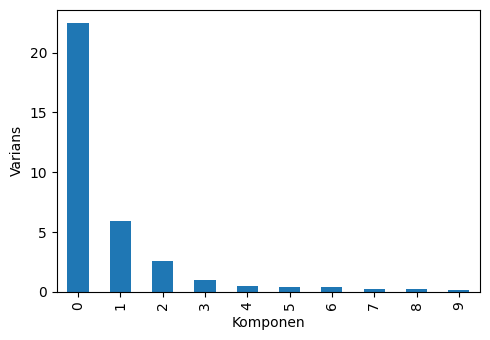

Loadings 2 komponen pertama (dibulatkan):
           0      1
GOOGL  0.857 -0.478
AMZN   0.445  0.874
AAPL   0.072  0.021
MSFT   0.036  0.006
CSCO   0.029  0.003
INTC   0.027  0.006
CVX    0.090  0.037
XOM    0.080  0.021
SLB    0.110  0.030
COP    0.058  0.024
JPM    0.071  0.009
WFC    0.053  0.009
USB    0.042  0.006
AXP    0.079  0.024
WMT    0.040  0.007
TGT    0.064  0.025
HD     0.051  0.033
COST   0.071  0.034


In [51]:
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
        'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(5, 3.5))
ax.set_xlabel('Komponen'); ax.set_ylabel('Varians')
plt.tight_layout(); plt.show()

print('Loadings 2 komponen pertama (dibulatkan):')
print(pd.DataFrame(sp_pca1.components_[0:2], columns=syms).T.round(3))

Dua komponen pertama hampir **sepenuhnya didominasi** oleh GOOGL dan AMZN, karena variansnya jauh lebih besar dari saham lain. PCA hanya "menemukan" bahwa kedua saham itu bervariasi paling banyak, bukan struktur pasar yang menarik.

**Solusi:**
- **Skalakan** variabel (misalnya normalisasi), atau setara dengan memakai matriks **korelasi** alih-alih matriks kovarians dalam PCA.
- Keluarkan variabel dominan dan analisis secara terpisah.
- Pakai return dalam **persen** daripada dalam dolar.

Namun, dalam beberapa kasus, variabel dominan justru mencerminkan sesuatu yang **memang penting** (misalnya fluktuasi yang benar-benar besar). Keputusan scaling sebaiknya berdasarkan konteks analisis.

In [52]:
# Solusi: PCA setelah standardisasi (setara dengan PCA pada matriks korelasi)
top_sp1_std = preprocessing.StandardScaler().fit_transform(top_sp1)
sp_pca_std = PCA().fit(top_sp1_std)
print('Loadings PC1 setelah standardisasi:')
print(pd.Series(sp_pca_std.components_[0], index=syms).round(3).to_string())

Loadings PC1 setelah standardisasi:
GOOGL    0.220
AMZN     0.186
AAPL     0.176
MSFT     0.236
CSCO     0.252
INTC     0.237
CVX      0.253
XOM      0.257
SLB      0.216
COP      0.232
JPM      0.267
WFC      0.264
USB      0.260
AXP      0.266
WMT      0.217
TGT      0.231
HD       0.222
COST     0.227


Setelah standardisasi, PC1 kembali mencerminkan **rata-rata pasar**, dengan bobot yang tersebar di semua saham, bukan hanya didominasi GOOGL dan AMZN.

### Data Kategorikal dan Gower's Distance
Untuk data **campuran** (numerik dan kategorikal), jarak Euclidean atau Manhattan tidak cocok, karena:
- one-hot encoding membuat variabel biner 0/1 yang skalanya berbeda dari variabel numerik, dan
- variabel kategorikal dengan banyak kategori akan menghasilkan banyak kolom dummy yang mendominasi jarak.

**Gower's distance** (diusulkan J.C. Gower, 1971) menangani ini dengan:
1. Untuk variabel **numerik dan ordinal**: jarak = **selisih absolut dibagi rentang** variabel ($|x_i - x_j| / \text{range}$), sehingga bernilai 0–1.
2. Untuk variabel **kategorikal**: jarak = **0** jika kategorinya sama, **1** jika berbeda.
3. Hitung **rata-rata** jarak dari semua variabel → nilai 0–1.

Contoh dari buku: 5 pinjaman default dengan dua variabel numerik (`dti`, `payment_inc_ratio`) dan dua kategorikal (`home_`, `purpose_`).

In [53]:
x = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].iloc[0:5].reset_index(drop=True)
x

,dti,payment_inc_ratio,home_,purpose_
0,1.00,2.39320,RENT,major_purchase
1,5.55,4.57170,OWN,small_business
2,18.08,9.71600,RENT,other
3,10.08,12.21520,RENT,debt_consolidation
4,7.06,3.90888,RENT,other


In [54]:
def gower_distance(df):
    """Matriks Gower's distance untuk DataFrame berisi kolom numerik dan kategorikal."""
    n = len(df)
    dist = np.zeros((n, n))
    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            values = df[col].to_numpy(dtype=float)
            rng = values.max() - values.min()
            d = np.abs(values[:, None] - values[None, :]) / (rng if rng > 0 else 1)
        else:
            values = df[col].astype(str).to_numpy(dtype=object)
            d = (values[:, None] != values[None, :]).astype(float)
        dist += d
    return dist / len(df.columns)

pd.DataFrame(gower_distance(x)).round(4)

,0,1,2,3,4
0,0.0000,0.6220,0.6864,0.6329,0.3773
1,0.6220,0.0000,0.8143,0.7609,0.5390
2,0.6864,0.8143,0.0000,0.4307,0.3091
3,0.6329,0.7609,0.4307,0.0000,0.5056
4,0.3773,0.5390,0.3091,0.5056,0.0000


Semua jarak bernilai antara 0 dan 1. Pasangan pinjaman dengan jarak kecil punya karakteristik yang mirip di semua variabel, baik numerik maupun kategorikal.

**Catatan:** di sini rentang (range) dihitung dari 5 record ini saja. Dalam praktik, rentang biasanya dihitung dari **seluruh data**. Implementasi Gower siap pakai juga tersedia di paket Python `gower`.

Gower's distance bisa dipakai sebagai input **hierarchical clustering**. Contoh: 1.000 pinjaman default yang diambil acak.

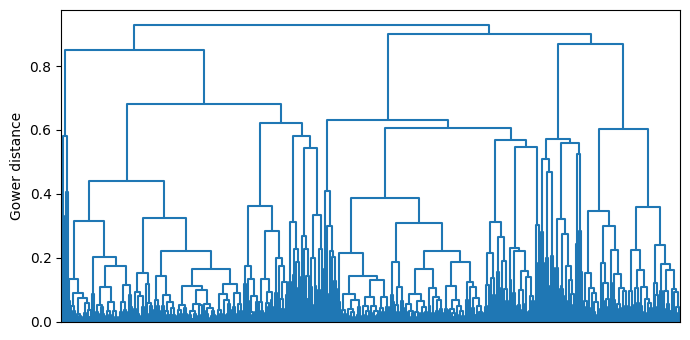

home_    MORTGAGE  OWN  RENT
cluster                     
1               2    3   420
2             350    0     0
3               0   68     0
4              74    0    83


In [55]:
sample = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].sample(1000, random_state=1).reset_index(drop=True)
D = gower_distance(sample)
Z_g = linkage(squareform(D, checks=False), method='complete')

fig, ax = plt.subplots(figsize=(7, 3.5))
dendrogram(Z_g, no_labels=True, ax=ax, color_threshold=0)
ax.set_ylabel('Gower distance')
plt.tight_layout(); plt.show()

sample['cluster'] = fcluster(Z_g, 4, criterion='maxclust')
print(pd.crosstab(sample['cluster'], sample['home_']))

Struktur paling atas dendrogram dan tabel silang menunjukkan bahwa cluster terutama terbentuk berdasarkan **variabel kategorikal** (misalnya `home_`: MORTGAGE, OWN, RENT). Ini mengarah ke masalah berikutnya.

### Masalah Clustering Data Campuran
K-Means dan PCA paling cocok untuk variabel **kontinu**. Untuk data campuran, buku menyarankan untuk berhati-hati:
- Variabel **biner/kategorikal** cenderung **mendominasi** pembentukan cluster, karena jaraknya selalu 0 atau 1 (perbedaan "maksimum"), sedangkan variabel numerik biasanya hanya berbeda sedikit.
- Akibatnya, cluster sering hanya mencerminkan kategori, bukan pola menarik dari variabel numerik.

Contoh dari buku: K-Means pada data pinjaman dengan variabel numerik **plus** variabel biner (dummy dari `home_` dan `pub_rec_zero`).

In [56]:
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns], dtype=int)

scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=df.columns)
centers.round(3)

,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT
0,17.456,8.423,1.000,1.000,-0.0,0.000
1,16.992,9.105,1.000,0.000,-0.0,1.000
2,17.198,9.267,0.918,0.000,1.0,0.000
3,16.505,8.064,-0.000,0.516,-0.0,0.484


Cluster yang terbentuk hampir sepenuhnya ditentukan oleh **variabel biner**: nilai `home__MORTGAGE`, `home__OWN`, `home__RENT`, dan `pub_rec_zero` di centroid hampir semuanya 0 atau 1. Artinya K-Means pada dasarnya hanya memisahkan data berdasarkan kategori, sedangkan variabel numerik (`dti`, `payment_inc_ratio`) hampir tidak berperan.

**Solusi yang disarankan:**
- **Lakukan clustering terpisah** untuk tiap kategori (misalnya cluster pinjaman pemilik rumah dan penyewa secara terpisah), atau
- Gunakan hanya variabel **numerik** untuk clustering, lalu **profilkan** cluster dengan variabel kategorikal setelahnya, atau
- Gunakan metode khusus data campuran seperti **K-Prototypes** atau hierarchical clustering dengan **Gower's distance** (dengan tetap mewaspadai dominasi kategori).

## Ringkasan Bab 7

- **Unsupervised learning** mencari struktur dalam data **tanpa label**: clustering, reduksi dimensi, dan eksplorasi. Hasilnya juga bisa menjadi input untuk model supervised.
- **PCA** merangkum variabel numerik yang berkorelasi menjadi **principal components** yang tidak berkorelasi, diurutkan berdasarkan varians yang dijelaskan. **Loadings** membantu menafsirkan komponen, dan **screeplot** membantu memilih jumlah komponen. Pada data saham, PCA mengungkap faktor pasar dan sektor industri.
- **Correspondence analysis** adalah padanan PCA untuk data **kategorikal** (tabel kontingensi), divisualisasikan dengan **biplot**.
- **K-Means** membagi data ke K cluster dengan meminimalkan within-cluster sum of squares. Algoritmanya iteratif (tetapkan → hitung ulang mean) dan sebaiknya dijalankan berkali-kali. K bisa dipilih dengan **elbow method**, meski di data nyata elbow sering tidak jelas.
- **Hierarchical clustering** membangun hierarki cluster yang divisualisasikan dengan **dendrogram**, tanpa perlu menentukan K di awal. Pilihan **linkage** (single, average, complete, Ward) sangat memengaruhi hasil.
- **Model-based clustering** (Gaussian mixture) mengasumsikan data berasal dari campuran distribusi normal multivariat dan bisa menemukan cluster berdasarkan perbedaan **varians**, bukan hanya mean. Jumlah cluster dipilih dengan **BIC**.
- **Scaling** sangat penting: variabel berskala atau bervarians besar akan **mendominasi** jarak dan PCA. Gunakan normalisasi atau matriks korelasi.
- Untuk **data campuran**, gunakan **Gower's distance**, dan waspadai variabel kategorikal/biner yang cenderung mendominasi pembentukan cluster.

